# Bound vs unbound antibody RMSDs

How far is the unbound antibody of each benchmark case from its bound form? This notebook measures it for
the **16 antibody–antigen cases** of the [Protein–Protein Docking Benchmark 5.5](https://zlab.wenglab.org/benchmark/)
that `array/launch_wf.py` runs, on **the structures the workflow itself docks**, checks the numbers against the
benchmark's published **I-RMSD**, and reads the docking results back next to them.

The benchmark defines the I-RMSD as:

> The I-RMSD was calculated by superposing the unbound component proteins onto their bound forms, using the
> Cα atoms for residues that had any atom within 10 Å of any atom of the binding partner.

That fixes what the previous version of this notebook swept over: **one interface** (10 Å, any atom, found on
the bound complex), **Cα atoms**, and **both partners**, each fitted on its own interface residues. The
cutoff sweep, the 5 Å interface and the antibody-only stand-in for the I-RMSD are gone.

## Where the structures come from

Every case is prepared by the workflow's own code, from the configuration `launch_wf.py` writes for it
(`output/exploration/rmsds/prep/case_<i>/workflow.yml`):

| step | what | code |
|---|---|---|
| `step0_*` | download: biological assembly 1, unless the identifier names a model | `workflow.download_pdbs` |
| `step1_repair_*` | unbound antibody and antigen: missing residues built by Modeller, observed ones kept (`fix_known`) | `utils.repair_structure` |
| `step1_0`–`step1_6` | cleaning; antibody fused into chain A, antigen into chain B, chains in the identifier's order; reference complex A + B | `haddock.prepare_structures` |
| `step2_19` | IMGT numbering of the repaired antibody | ANARCII (`biobb_haddock`) |

The analysis then reuses `haddock_interface` (the interface, here at 10 Å instead of stage 1's 3.9 Å),
`utils.map_contact_residues` (which bound residue is which unbound residue) and `cdr.imgt_region_ri` with
`cdr.CDR_RANGES` / `cdr.FRAMEWORK_RANGES` (the CDRs and the framework, as stage 2 defines them). Everything
else, from the tables to the figures, is in `ab_rmsds.py`; the cells below call it.

As a control, the benchmark's own bound and unbound files (`output/benchmark5.5`) go through the same
steps 1_0–1_6 and the same I-RMSD code.

## What is measured

* **I-RMSD** of both partners, per the definition above, and its antibody and antigen sides.
* **Antibody regions**, Cα only: `fv`, `framework`, `cdr_all`, `H1`–`L3` (IMGT), `full` (every paired residue,
  constant domains included) and `interface` (antibody side of the 10 Å interface), under three superpositions:

| scheme | fitted on | answers |
|---|---|---|
| `self` | the measured atoms | how much the region's own shape changes; a lower bound on the other two |
| `fv_fw` | Fv framework Cα | how far the region moves in the antibody's own frame; the number for CDRs |
| `full` | every paired Cα | the same in a whole-Fab frame, so it also absorbs the elbow angle |

* **Docking** (section 10): the DockQ the right answer gets against the workflow's reference, and what the
  CDR ensembles change in the cluster runs, next to the CDR displacement.

In [1]:
import ab_rmsds as ar

ar.setup_figures()
print('cases      :', len(ar.COMPLEXES))
print('structures :', ar.PREP)
print('results    :', ar.RES)
print('figures    :', ar.FIG)
print('docking    :', ar.HPC_RESULTS)

cases      : 16
structures : /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/prep
results    : /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/results
figures    : /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/figures
docking    : /home/rchaves/repo/biobb/biobb_wf_antibody/output/hpc_results


## 1. Preparing the cases

The first run downloads the entries and runs the Modeller repair, around 10 s per case; afterwards
everything is read from disk. A case is prepared again when its entry in `COMPLEXES` changes (a pinned model,
say) or with `ar.prepare_case(i, force=True)`. `*_modelled` counts the residues the repair built, i.e. those
whose Cα is not where a Cα of the downloaded entry is.

In [2]:
files, bench_files, modelled, cases = ar.load_cases()
cases[['reference', 'antibody', 'antigen', 'benchmark_complex', 'difficulty', 'antibody_modelled', 'antigen_modelled']]

,reference,antibody,antigen,benchmark_complex,difficulty,antibody_modelled,antigen_modelled
case_idx,,,,,,,
0,2VXT_HL:I,2VXU_HL,1J0S_A(6),2VXT_HL:I,rigid,0,0
1,2W9E_HL:A,2W9D_HL,1QM1_A,2W9E_HL:A,rigid,0,0
2,3EOA_LH:I,3EO9_LH,3F74_A,3EOA_LH:I,rigid,5,0
3,3HMX_LH:AB,3HMW_LH,1F45_AB,3HMX_LH:AB,rigid,3,69
4,3MXW_LH:A,3MXV_LH,3M1N_A,3MXW_LH:A,rigid,0,0
5,5VPG_CD:A,3RVT_CD,3F5V_A,3RVW_CD:A,rigid,0,1
6,4DN4_LH:M,4DN3_LH,1DOL_A,4DN4_LH:M,rigid,6,0
7,4FQI_HL:ABEFCD,4FQH_HL,2FK0_ABCDEF,4FQI_HL:ABEFCD,rigid,0,0
8,4G6J_HL:A,4G5Z_HL,4I1B_A,4G6J_HL:A,rigid,0,0


## 2. The interface

`haddock_interface` at 10 Å on the bound complex of step1_6 (chain A antibody, chain B antigen). It is
checked against an independent any-atom search, MDAnalysis `around 10`, so the benchmark's "any atom within
10 Å of any atom of the binding partner" is what is used, not assumed (`interface_table` raises otherwise).

In [3]:
iface = ar.interface_table(files)
print(f'interface size: antibody {iface.antibody.min()}-{iface.antibody.max()}, '
      f'antigen {iface.antigen.min()}-{iface.antigen.max()} residues; '
      f'{iface.disagree_with_mdanalysis.sum()} residues differ from the MDAnalysis search')
iface.T

interface size: antibody 45-76, antigen 27-80 residues; 0 residues differ from the MDAnalysis search


case_idx,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
antibody,76,66,51,72,71,50,56,45,71,59,69,69,66,69,49,70
antigen,54,32,43,54,59,50,29,80,55,53,78,55,43,56,27,49
disagree_with_mdanalysis,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 3. I-RMSD against the published values

Two sets of structures go through the same code:

* **benchmark files** — the benchmark's own `_r_b`, `_l_b`, `_r_u`, `_l_u`. Same complexes, same crystal
  forms (3RVW for the 3RVT case), so they test the definition and the code: they should give the published
  column.
* **workflow** — what stage 1 prepares and HADDOCK3 docks. Where it differs from the benchmark files, the
  difference comes from the preparation: the entry or the model downloaded, the repair, or the residue
  pairing.

`*_ab` and `*_ag` are the antibody and antigen sides of the pooled value.

In [4]:
irm = ar.irmsd_table(cases, files, bench_files, modelled)
ar.report_irmsd(irm)
irm[ar.IRMSD_COLUMNS].round(2)

benchmark files - published: |diff| <= 0.01 A in 15/16, largest 0.03 A (4G6M)
workflow - benchmark files : |diff| <= 0.01 A in 15/16; differ in
    4FQI/4FQH: 1.12 vs 1.08 A (antibody side 0.75 vs 0.75, antigen side 1.28 vs 1.23)
interface residues without an unbound counterpart (workflow): 1
interface residues built by the repair (workflow)          : 0


,ref_code,unb_code,benchmark_irmsd,bench_irmsd,bench_irmsd_ab,bench_irmsd_ag,wf_irmsd,wf_irmsd_ab,wf_irmsd_ag
case_idx,,,,,,,,,
0,2VXT,2VXU,1.33,1.32,0.38,2.00,1.32,0.38,2.00
1,2W9E,2W9D,1.13,1.13,0.83,1.57,1.13,0.83,1.57
2,3EOA,3EO9,0.39,0.39,0.37,0.42,0.39,0.37,0.42
3,3HMX,3HMW,0.73,0.73,0.55,0.91,0.73,0.55,0.91
4,3MXW,3MXV,0.48,0.48,0.44,0.53,0.48,0.44,0.53
5,5VPG,3RVT,0.50,0.50,0.47,0.53,0.50,0.47,0.53
6,4DN4,4DN3,0.81,0.81,0.96,0.40,0.81,0.96,0.40
7,4FQI,4FQH,1.08,1.08,0.75,1.23,1.12,0.75,1.28
8,4G6J,4G5Z,0.61,0.61,0.39,0.81,0.61,0.39,0.81


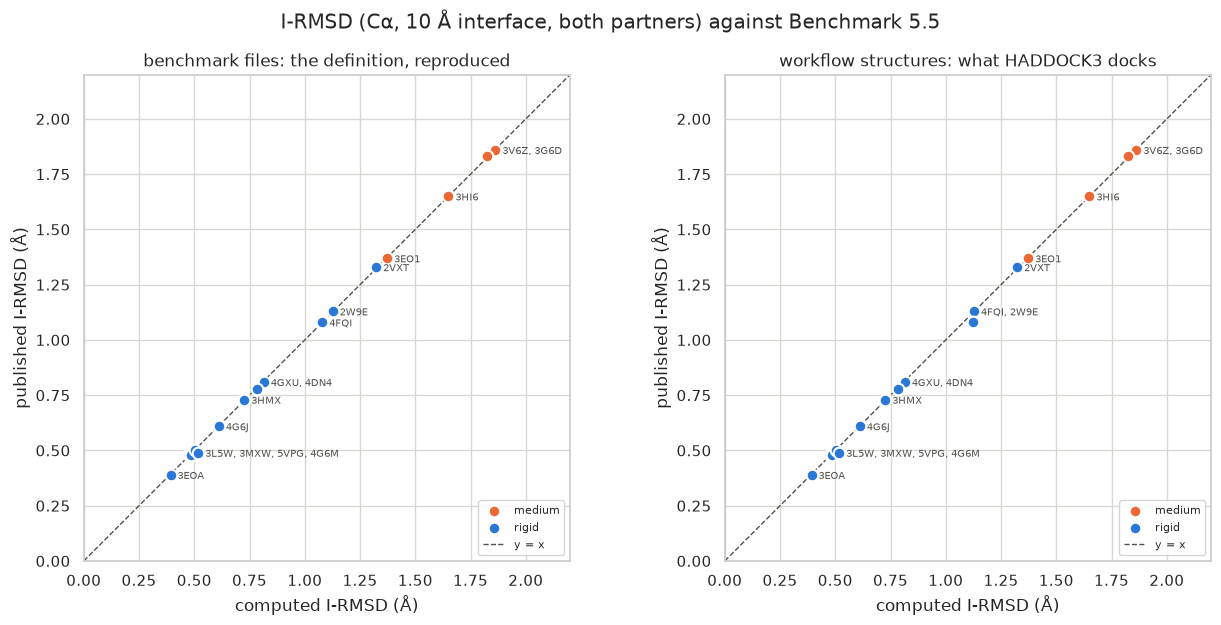

In [5]:
ar.plot_irmsd_vs_published(irm)

Which partner carries the I-RMSD? The benchmark value pools both sides, so a case can be "medium" because of
the antigen alone. Benchmark files, so that the workflow's own pairing problems (above) do not enter.

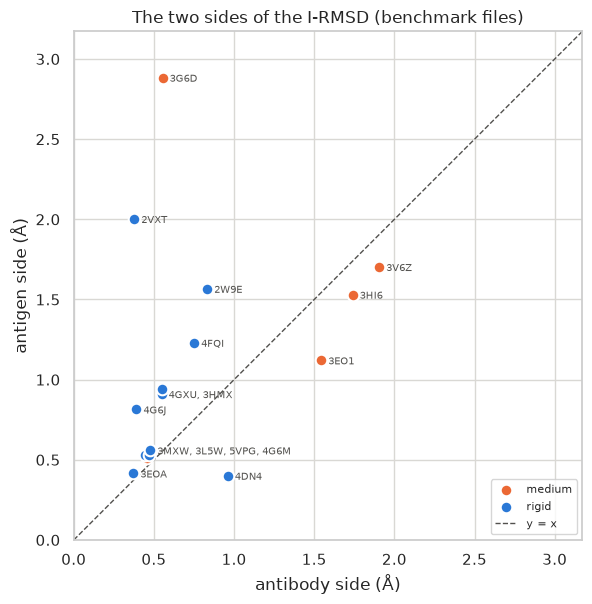

larger side per case: {'antigen': np.int64(12), 'antibody': np.int64(4)}
medium: median antibody side 1.54 A, antigen side 1.53 A
rigid : median antibody side 0.48 A, antigen side 0.81 A


In [6]:
ar.plot_irmsd_sides(irm)
ar.report_sides(irm)

## 4. Antibody regions

The whole bound antibody (chain A of step1_6) is paired with the prepared unbound one by
`utils.map_contact_residues` over every residue. Two kinds of pair are left out rather than trusted:
residues that equally scoring alignments pair differently (a gap next to repeated residues), and pairs that
cross from one antibody chain to the other. The fused chain A hides the light/heavy junction, and in 4DN4 the
alignment paired the light chain's C-terminal Gly with the heavy chain's first Val, 55 Å away.

The regions are defined on the unbound side, from ANARCII's IMGT numbering through `cdr.imgt_region_ri`, and
carried to the bound side by that pairing. The framework is `cdr.FRAMEWORK_RANGES` clipped at IMGT 128, the
end of the V domain: the ranges run to 129, which ANARCII gives to the first CH1/CL residue, a residue that
follows the elbow (7.9 Å off in 3EOA) and would add up to 0.22 Å to the framework RMSD. CDR-L2 is 3 residues
wide in every one of these antibodies, too few for a `self` fit, so it is only measured in a fixed frame.

The table below is the number of residues in each extent, per case.

In [7]:
df, dfres, ab = ar.antibody_tables(files, modelled, cases)
ar.report_pairing(files, df, ab)

528 RMSD rows (11 extents x 3 schemes x 16 cases)
bound antibody residues left unpaired (no counterpart, or ambiguous): {0: 2, 1: 3, 2: 2, 3: 0, 4: 0, 5: 0, 6: 2, 7: 1, 8: 0, 9: 1, 10: 0, 11: 1, 12: 1, 13: 1, 14: 2, 15: 0}
pairs dropped for crossing the light/heavy junction: {6: 1}
paired residues the repair built: {3: 3, 6: 1, 14: 5, 15: 4}


case_idx,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
extent,,,,,,,,,,,,,,,,
fv,220.0,222.0,229.0,227.0,227.0,229.0,227.0,230.0,226.0,228.0,236.0,229.0,230.0,225.0,229.0,238.0
framework,180.0,180.0,181.0,181.0,181.0,181.0,179.0,178.0,181.0,181.0,178.0,181.0,180.0,179.0,181.0,181.0
cdr_all,40.0,42.0,48.0,46.0,46.0,48.0,48.0,52.0,45.0,47.0,58.0,48.0,50.0,46.0,48.0,57.0
H1,8.0,8.0,8.0,8.0,8.0,9.0,8.0,8.0,8.0,10.0,8.0,8.0,8.0,8.0,10.0,8.0
H2,8.0,8.0,8.0,8.0,8.0,7.0,8.0,8.0,8.0,7.0,8.0,8.0,8.0,8.0,7.0,8.0
H3,6.0,9.0,14.0,12.0,12.0,14.0,12.0,14.0,11.0,12.0,19.0,13.0,15.0,13.0,13.0,16.0
L1,6.0,5.0,6.0,6.0,6.0,6.0,7.0,8.0,6.0,6.0,8.0,7.0,6.0,6.0,6.0,12.0
L2,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
L3,9.0,9.0,9.0,9.0,9.0,9.0,10.0,11.0,9.0,9.0,12.0,9.0,10.0,8.0,9.0,10.0


In [8]:
summary = ar.summary_table(irm, df)
summary.round(2)

,ref_code,unb_code,difficulty,benchmark_irmsd,bench_irmsd,wf_irmsd,wf_irmsd_ab,wf_irmsd_ag,framework,fv,full,fv_in_full,interface_ab,cdr_self,cdr_fw,H3_fw
case_idx,,,,,,,,,,,,,,,,
2,3EOA,3EO9,rigid,0.39,0.39,0.39,0.37,0.42,0.67,0.63,4.73,4.56,0.37,0.37,0.45,0.50
4,3MXW,3MXV,rigid,0.48,0.48,0.48,0.44,0.53,0.41,0.44,1.10,1.00,0.44,0.50,0.58,0.73
14,3L5W,3L7E,medium,0.48,0.48,0.48,0.46,0.51,0.62,0.60,1.27,1.15,0.46,0.48,0.50,0.45
9,4G6M,4G6K,rigid,0.49,0.52,0.52,0.48,0.56,0.43,0.41,0.51,0.51,0.48,0.26,0.37,0.30
5,5VPG,3RVT,rigid,0.50,0.50,0.50,0.47,0.53,0.35,0.39,0.59,0.51,0.47,0.48,0.51,0.68
8,4G6J,4G5Z,rigid,0.61,0.61,0.61,0.39,0.81,0.63,0.60,3.11,2.87,0.39,0.40,0.46,0.44
3,3HMX,3HMW,rigid,0.73,0.73,0.73,0.55,0.91,0.62,0.63,3.43,3.18,0.55,0.46,0.69,0.46
10,4GXU,4GXV,rigid,0.78,0.78,0.78,0.55,0.94,0.48,0.52,3.17,3.11,0.55,0.53,0.65,0.79
6,4DN4,4DN3,rigid,0.81,0.81,0.81,0.96,0.40,0.67,0.82,3.40,3.34,0.96,1.03,1.31,0.44


## 5. Checks

1. **Identity** — the bound complex as its own unbound partner gives an I-RMSD of 0: pairing, interface and fit
   all agree with themselves.
2. **Lower bound** — `self` is the best fit of the measured atoms, so no fixed frame can give less.
3. **Nesting** — `framework` + `cdr_all` = `fv`, the six CDRs add up to `cdr_all`, `fv` ⊆ `full`.
4. **Two pairings agree** — the antibody side of the I-RMSD pairs the interface residues on their own, the
   `interface` extent pairs them inside the whole chain; both must give the same number.

In [9]:
ar.run_checks(files, df, summary)

1. identity: I-RMSD of the bound complex against itself = 8.8e-15 A
2. lower bound: no fixed-frame value below its self value (160 rows)
3. nesting: framework + cdr_all == fv, H1 + ... + L3 == cdr_all, fv <= full
4. antibody side of the I-RMSD vs interface extent: largest difference 0.0e+00 A


## 6. Whole antibody vs CDR loops

Two framings that must not be mixed:

* `self` — each region best-fitted onto itself: its *internal shape change* only;
* `fv_fw` — the antibody placed by its Fv framework and nothing refitted: the *actual displacement*, which is
  what a rigid-body docking run starting from the unbound structure has to live with.

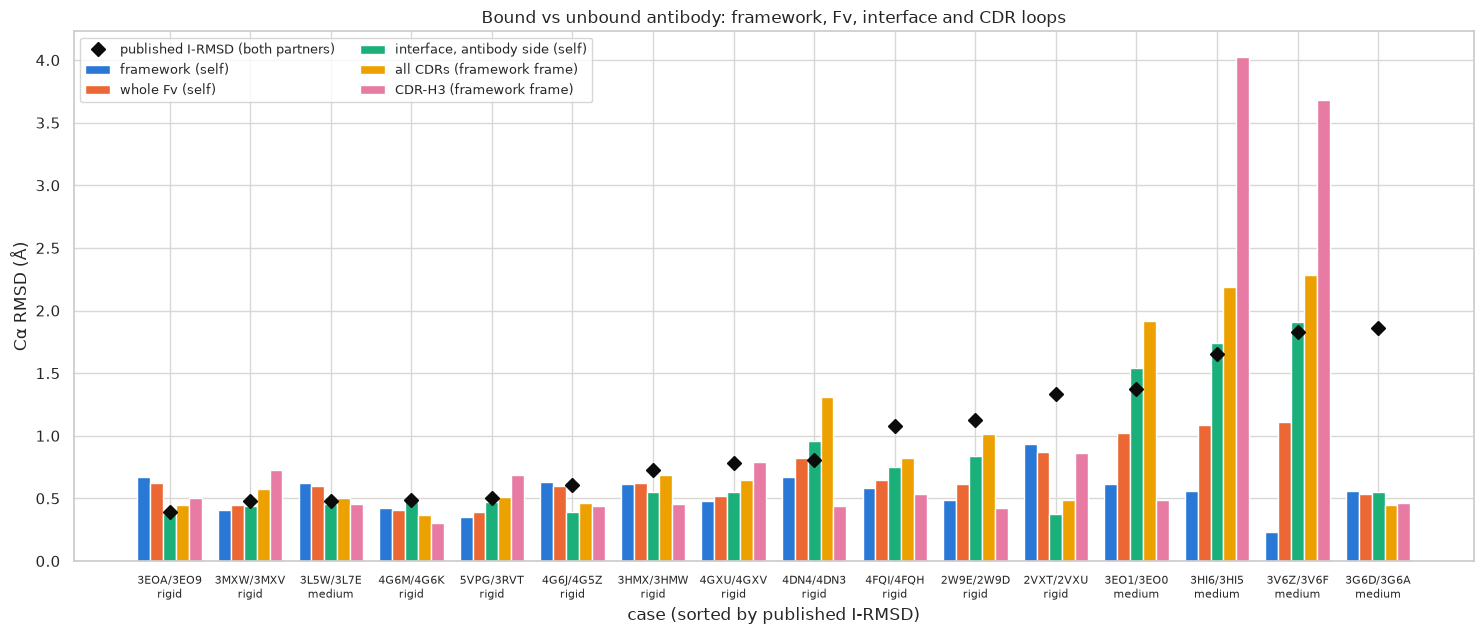

CDR displacement / framework RMSD, per case:
  median 1.37x, range 0.52-9.71x
  CDRs move more than the framework in 10/16 cases
  Wilcoxon signed-rank (CDR vs framework): p = 0.1


In [10]:
ar.plot_case_bars(summary)
ar.report_cdr_vs_framework(summary)

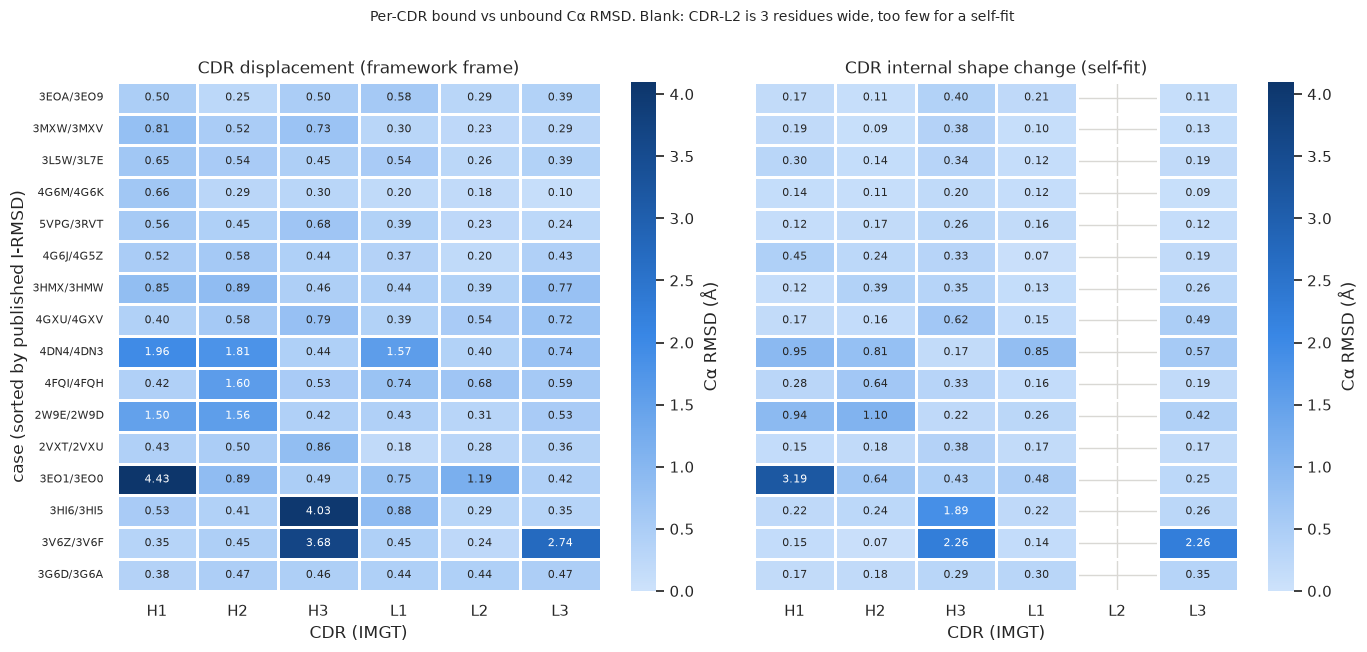

median displacement in the framework frame, per CDR (A):
H1    0.55
H2    0.53
H3    0.49
L1    0.44
L2    0.29
L3    0.43

CDR-H3 is the largest of the six in 5/16 cases
largest single-loop displacements: 3EO1 H1 4.43 A, 3HI6 H3 4.03 A, 3V6Z H3 3.68 A, 3V6Z L3 2.74 A


In [11]:
ar.plot_cdr_heatmap(df, summary)
ar.report_per_cdr(df, cases)

## 7. Benchmark difficulty

The benchmark classes a case by its I-RMSD (and the change in buried surface), both partners together.
Does the class show up in the antibody alone? The table holds the medians.

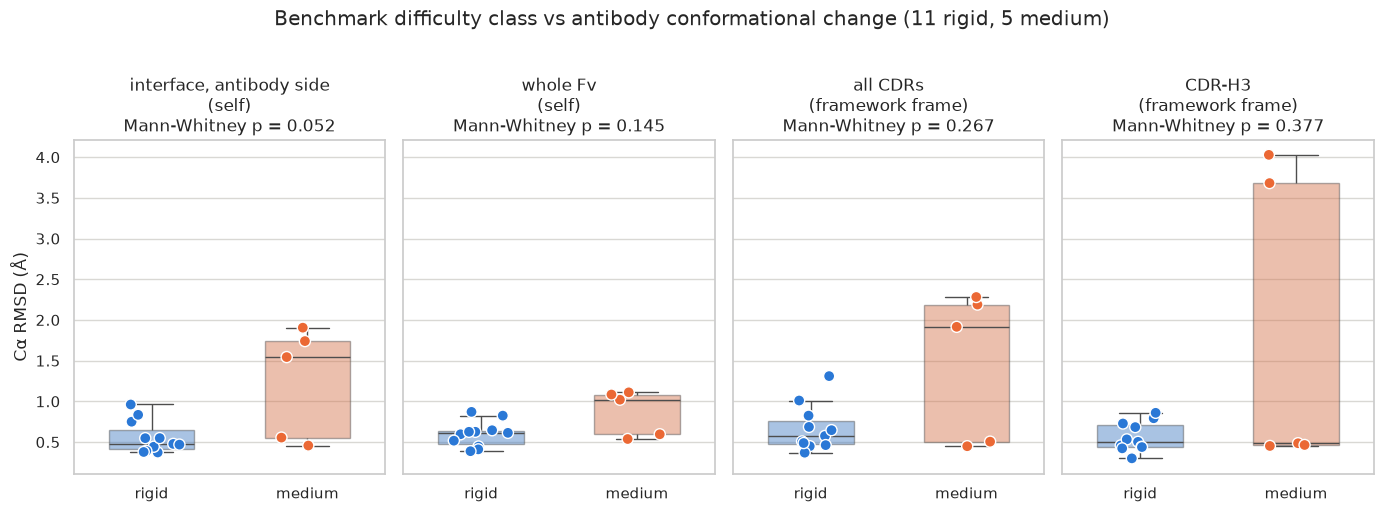

,wf_irmsd_ab,fv,cdr_fw,H3_fw
difficulty,,,,
medium,1.54,1.02,1.92,0.49
rigid,0.48,0.61,0.58,0.50


In [12]:
ar.plot_difficulty(summary)

## 8. Why "whole antibody" needs qualifying

`full / self`, a whole-Fab RMSD over every paired residue, is far above the Fv's: the elbow angle between the
variable and the constant modules differs between crystal forms, and one rigid superposition cannot satisfy
both modules. The left panel shows it directly, the Fv measured in a whole-Fab fit against the Fv fitted on
itself. The right panel splits the CDR motion: height above the diagonal is displacement a rigid re-placement
of the loops would absorb; position along it is change of loop shape.

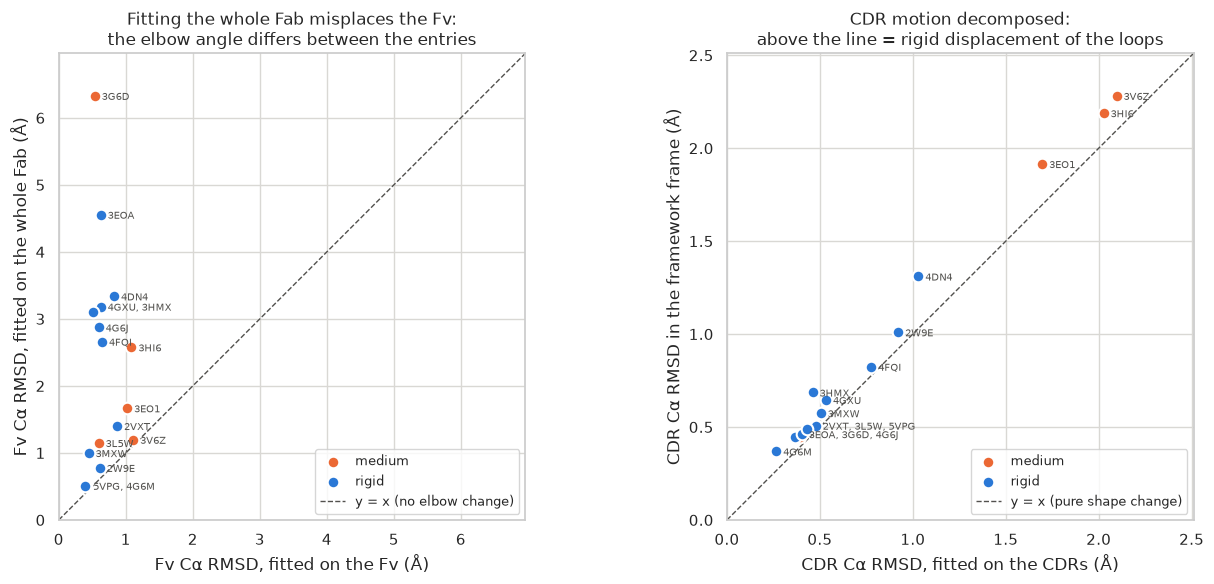

whole-Fab RMSD (full/self)   : 0.51 - 7.01 A (median 2.53)
whole-Fv RMSD (fv/self)      : 0.39 - 1.11 A (median 0.62)
Fv residual in a whole-Fab fit: 0.51 - 6.33 A (median 2.12)
the whole-Fab fit inflates the Fv RMSD by more than 50% in 12/16 cases


In [13]:
ar.plot_elbow(summary)
ar.report_elbow(summary)

## 9. The largest CDR-H3 displacement, superposed

The unbound antibody is placed on the bound one by its **Fv framework Cα only**, and nothing is refitted, so
the viewer shows the actual displacement of the loop, not a best fit of the loop onto itself. Both files are
the prepared ones (chain A, numbered from 1), so the loop is selected by the residues the IMGT ranges
resolved to.

largest CDR-H3 displacement: case 13, 3HI6_XY:B (bound) vs 3HI5_HL (unbound) = 4.03 A Ca RMSD
fitted on 179 framework Ca (no CDR atom takes part in the fit)
superposed unbound antibody: /home/rchaves/repo/biobb/biobb_wf_antibody/output/exploration/rmsds/worst_H3_3HI5_on_3HI6.pdb
the loop tip moves furthest: IMGT 111 TRP at 8.13 A; its anchors (IMGT 105 and 117) stay within 0.55 A
11/13 loop residues are in the 10 A interface


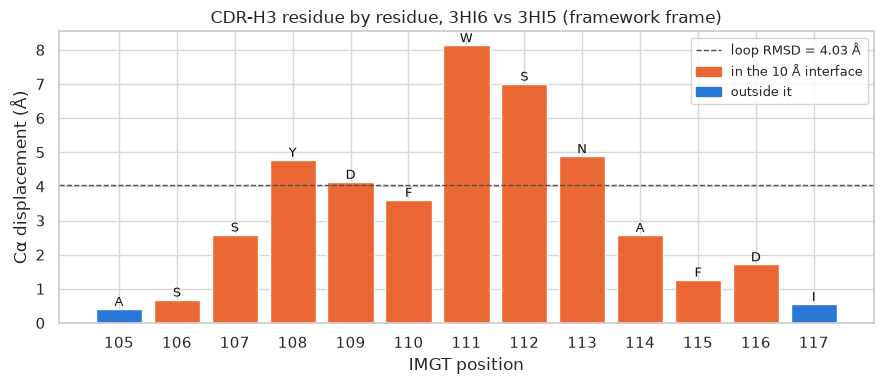

,resname,resid_bound,resid_unbound,in_interface,Ca displacement (A)
imgt,,,,,
105,ALA,97,96,False,0.41
106,SER,98,97,True,0.68
107,SER,99,98,True,2.59
108,TYR,100,99,True,4.78
109,ASP,101,100,True,4.13
110,PHE,102,101,True,3.61
111,TRP,103,102,True,8.13
112,SER,104,103,True,7.01
113,ASN,105,104,True,4.89


In [14]:
worst = ar.worst_h3(cases, files, df, dfres, ab)
h3_table = ar.report_worst_h3(worst)
ar.plot_h3_profile(worst)
h3_table

In [15]:
# blue cartoon = bound Fv,  grey cartoon = unbound Fv (superposed),  faint = antigen
# green sticks = bound CDR-H3,  orange sticks = unbound CDR-H3,  sphere = the loop tip's Ca
ar.h3_view(worst)

NGLWidget()

## 10. Docking: the reference, and whether the CDR ensembles pay off

The cluster runs copied back to `output/hpc_results` hold 200 refined models per run, scored by the run's
own caprieval after emref. They are read here next to the RMSDs above, with two questions.

**Can a docked model score well at all?** The right answer is the benchmark's unbound partners where they
bind (the benchmark ships its `_u` files superposed on the bound complex), fused as stage 1 fuses the docking
input. It is scored by haddock3's caprieval, as the runs score their models, against the workflow's
reference (step1_6 as the current code prepares it) and against the benchmark's own bound files. Being
unbound, it cannot reach DockQ 1. Where the two references disagree, the reference is what limits the DockQ,
not the docking. They used to disagree in 4FQI and 4GXU (finding 8); `prepare_antigen` now joins the
antigen chains in the identifier's order, so they should agree everywhere.

In [16]:
pp = ar.perfect_pose_dockq(files, bench_files)
d = (pp.dockq_benchmark - pp.dockq_workflow).abs()
print(f'workflow vs benchmark reference: largest DockQ difference {d.max():.2f} ({cases.ref_code[d.idxmax()]})')
cases[['ref_code']].join(pp).round(2)

workflow vs benchmark reference: largest DockQ difference 0.01 (4FQI)


,ref_code,fnat_workflow,irmsd_workflow,lrmsd_workflow,dockq_workflow,fnat_benchmark,irmsd_benchmark,lrmsd_benchmark,dockq_benchmark
case_idx,,,,,,,,,
0,2VXT,0.65,1.48,2.52,0.69,0.65,1.48,2.52,0.69
1,2W9E,0.55,1.25,1.65,0.70,0.55,1.25,1.65,0.70
2,3EOA,0.33,2.99,1.47,0.50,0.33,2.99,1.47,0.50
3,3HMX,0.49,2.23,4.37,0.53,0.49,2.23,4.37,0.53
4,3MXW,0.80,0.82,0.54,0.86,0.80,0.82,0.54,0.86
5,5VPG,0.71,0.62,0.64,0.85,0.71,0.62,0.64,0.85
6,4DN4,0.44,2.52,1.51,0.56,0.44,2.52,1.51,0.56
7,4FQI,0.55,2.08,2.44,0.61,0.58,2.04,2.44,0.62
8,4G6J,0.60,2.00,0.81,0.65,0.60,2.00,0.81,0.65


The cluster runs of 4FQI and 4GXU were scored before that fix, against a reference whose protomers came in
file order. Their DockQ stays capped until they are run again (`ar.FILE_ORDER_REFERENCE` lists them; empty
it once the new tables are in `output/hpc_results`). The signature is in the models of every protocol: the
best fnat, and the lowest i-RMSD and L-RMSD any of the 200 models reaches.

In [17]:
dock = ar.docking_table(cases)
capped = cases.index[cases.ref_code.isin(ar.FILE_ORDER_REFERENCE)]
print('cases still scored against the file-order reference:', ', '.join(cases.ref_code[capped]) or 'none')
(dock[dock.case_idx.isin(capped)].set_index(['ref_code', 'protocol'])
 [['best_dockq', 'max_fnat', 'min_irmsd', 'min_lrmsd']].round(2))

cases still scored against the file-order reference: 4FQI, 4GXU


best_dockq  max_fnat  min_irmsd  min_lrmsd
ref_code protocol                                            
4FQI     baseline        0.28      0.61       2.92      30.02
         md              0.28      0.63       3.06      30.09
         awh             0.31      0.69       3.14      30.01
4GXU     baseline        0.29      0.81      10.93      32.34
         md              0.29      0.81      10.85      32.24
         awh             0.32      0.89      10.64      34.13

**Do the CDR ensembles pay off where the CDRs move?** Per case and protocol, from the emref models:

* `acceptable`: the fraction of the 200 models with DockQ ≥ 0.23, what the protocol samples;
* `top`: the acceptable models among the 10 best HADDOCK scores, what the scoring picks;
* `best_dockq`: the best model;
* `awh_start_dockq`: the baseline model stage 3 simulates with the antigen in place (the run's best
  cluster model), the start of the AWH ensemble.

The figure plots each ensemble's change against the baseline docking. 3HMX has no ensemble runs yet, and the
DockQ of the cases still scored against the file-order reference is not comparable with the others (hollow).

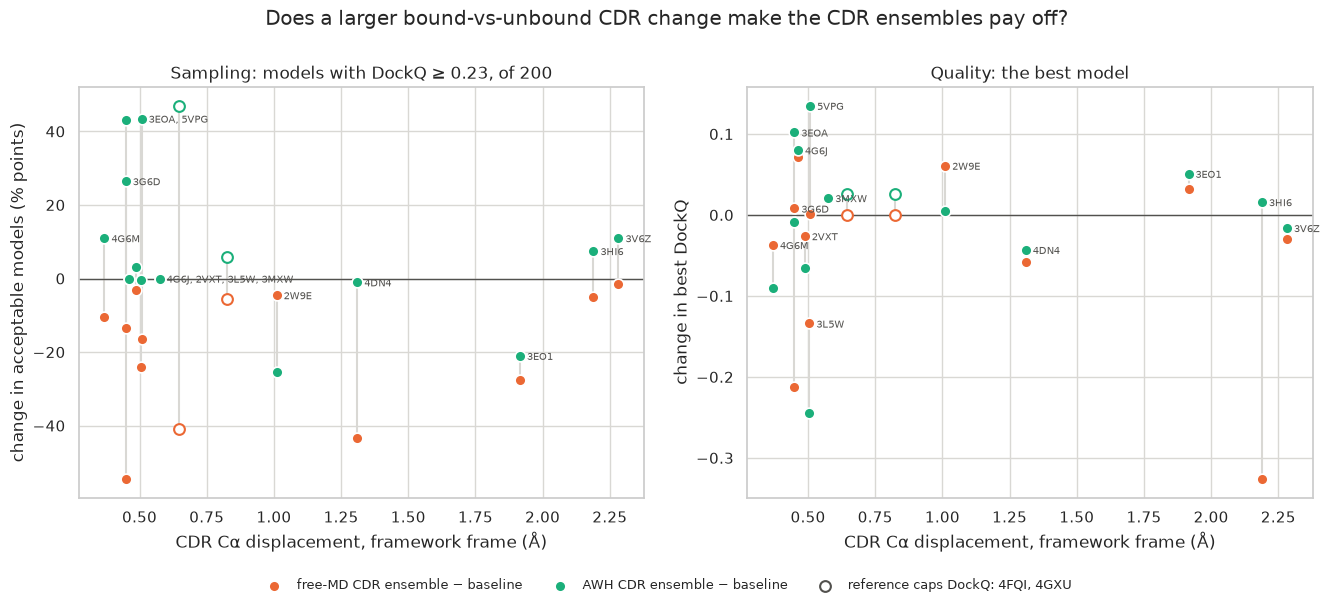

free-MD CDR ensemble vs CDR displacement, 15 cases: acceptable models rho = +0.08 (p = 0.78), best DockQ rho = -0.04 (p = 0.88), acceptable in top 10 rho = +0.01 (p = 0.98)
    more acceptable models than the baseline in 0, fewer in 13, as many in 2
AWH CDR ensemble vs CDR displacement, 15 cases: acceptable models rho = -0.33 (p = 0.23), best DockQ rho = +0.05 (p = 0.86), acceptable in top 10 rho = -0.06 (p = 0.84)
    more acceptable models than the baseline in 9, fewer in 4, as many in 2
AWH gain in acceptable models vs DockQ of the baseline model it starts from: rho = +0.02 (p = 0.95)
cases whose reference caps DockQ (their DockQ is not comparable): 4FQI, 4GXU


,ref_code,difficulty,cdr_fw,H3_fw,acceptable_baseline,acceptable_md,acceptable_awh,top_baseline,top_md,top_awh,best_dockq_baseline,best_dockq_md,best_dockq_awh,awh_start_dockq
case_idx,,,,,,,,,,,,,,
15,3V6Z,medium,2.28,3.68,0.28,0.26,0.39,4.0,5.0,9.0,0.45,0.42,0.43,0.18
13,3HI6,medium,2.19,4.03,0.05,0.00,0.12,0.0,0.0,0.0,0.42,0.09,0.43,0.09
11,3EO1,medium,1.92,0.49,0.85,0.57,0.64,2.0,0.0,4.0,0.54,0.57,0.59,0.05
6,4DN4,rigid,1.31,0.44,0.97,0.54,0.96,10.0,3.0,10.0,0.67,0.61,0.62,0.60
1,2W9E,rigid,1.01,0.42,0.32,0.27,0.06,6.0,0.0,0.0,0.47,0.53,0.47,0.37
7,4FQI,rigid,0.82,0.53,0.41,0.36,0.47,3.0,5.0,0.0,0.28,0.28,0.31,0.16
3,3HMX,rigid,0.69,0.46,0.42,NaN,NaN,10.0,NaN,NaN,0.56,NaN,NaN,0.56
10,4GXU,rigid,0.65,0.79,0.51,0.10,0.98,10.0,1.0,10.0,0.29,0.29,0.32,0.28
4,3MXW,rigid,0.58,0.73,1.00,1.00,1.00,10.0,10.0,10.0,0.82,0.84,0.84,0.77


In [18]:
gain = ar.docking_gain(dock, summary)
ar.plot_docking_gain(gain, capped)
ar.report_docking_gain(gain, capped)
gain[['ref_code', 'difficulty', 'cdr_fw', 'H3_fw', 'acceptable_baseline', 'acceptable_md', 'acceptable_awh',
      'top_baseline', 'top_md', 'top_awh', 'best_dockq_baseline', 'best_dockq_md', 'best_dockq_awh',
      'awh_start_dockq']].round(2)

## 11. Findings

**1. The benchmark's definition is reproduced exactly.** On the benchmark's own files, the I-RMSD as defined
(10 Å any-atom interface, each partner fitted on the Cα of its own interface residues, both pooled) equals the
published value within 0.01 Å in 15 of 16 cases; 4G6M reads 0.52 Å against 0.49. The published column is
now computed rather than correlated with (the antibody-only stand-in of the previous version reached
Pearson *r* = 0.67), so the cutoff sweep and the 5 Å interface have nothing left to decide. `haddock_interface`
at 10 Å lists exactly the any-atom interface in all 16 cases.

**2. The workflow's structures are the benchmark's in 15 of 16 cases, and the 16th differs by its altlocs.**
The assembly download, the Modeller repair (no repaired residue falls in any interface) and steps 1_0–1_6
give the same I-RMSD as the benchmark files within 0.01 Å. That includes 2VXT, now that `launch_wf.py` takes
1J0S model 6, the NMR model the benchmark uses (model 1 is 1.40 Å away), and the two HA trimers, now that
`prepare_antigen` joins the antigen chains in the identifier's order:

* **The fix.** `prepare_antigen` used to extract every antigen chain with one `pdb_selchain`, which keeps
  them in file order, whereas `prepare_antibody` takes them one by one in the order listed. 4GXU holds its
  protomers as A–F and 1RUZ as H–M; the identifier `4GXU_MN:ABEFCD` pairs E/F with J/K and C/D with L/M,
  but the reference came out ABCDEF, and the I-RMSD read **8.63 Å against 0.78**. 4FQI's assembly holds its three A/B protomers
  as three MODELs, which were fused in MODEL order (**2.13 Å against 1.08**). `prepare_antigen` now extracts
  the chains one by one in the listed order, as `prepare_antibody` does, and names the copies of an assembly
  among the antigen chains only (`utils.merge_models(text, chains)`), so 4FQI's MODELs become A/B, C/D and E/F
  as in the benchmark and `ABEFCD` names them. The docking inputs come out unchanged in all 16 cases, and so
  do the references of the other 14 (same atoms, same order).
* **4GXU: 0.78 Å**, the benchmark files' value.
* **4FQI: 1.12 Å against 1.08**, all on the antigen side (1.28 vs 1.23 Å). The bound entry has 1002 altloc
  atoms; the benchmark keeps altloc A everywhere and `pdb_selaltloc` the higher occupancy, B for 7 Cα per
  protomer. Prepared from the entry with altloc A kept, the workflow gives 1.079 Å, the benchmark's value.

Stage 1's 3.9 Å epitope lies on the first protomer in both trimers, so the docking restraints were the same
in either order; what the order changed is everything that pairs antigen residues between the reference and
the docking input: this I-RMSD, and caprieval's DockQ (finding 8).

**3. In most cases the antigen carries more of the I-RMSD than the antibody.** The antigen side is the larger
in 12 of 16 cases. 3G6D, the largest published value (1.86 Å), is all antigen: antibody 0.55 Å, antigen
2.88 Å (the NMR antigen 1IK0); 2VXT likewise (0.38 vs 2.00 Å). The previous version could only suspect this.
Of the five *medium* cases, 3EO1, 3HI6 and 3V6Z are antibody-driven (1.5–1.9 Å on the antibody side), 3G6D is
antigen-driven, and 3L5W (0.48 Å) is classed medium by criteria other than the I-RMSD.

**4. "RMSD of the whole antibody" is the Fab elbow.** Over every paired residue the whole-Fab Cα RMSD is
0.51–7.01 Å (median 2.53 Å), the Fv 0.39–1.11 Å (median 0.62 Å); a whole-Fab fit inflates the Fv RMSD by more
than 50 % in 12 of 16 cases. The Fv is the meaningful global measure for anything to do with binding.

**5. CDR loops move more than the framework, modestly.** In the Fv-framework frame the CDRs move 1.37× the
framework RMSD (median; 0.52–9.71×), more in 10 of 16 cases (Wilcoxon *p* = 0.10).

**6. CDR-H3 owns the extremes, not the median.** Median displacement per CDR: H1 0.55, H2 0.53, H3 0.49,
L1 0.44, L3 0.43, L2 0.29 Å; H3 is the largest of the six in 5 of 16 cases. The largest single loops are
3EO1 H1 (4.43 Å), 3HI6 H3 (4.03 Å), 3V6Z H3 (3.68 Å) and 3V6Z L3 (2.74 Å). 3HI6's H3 moves as a hinge: its
anchors (IMGT 105, 117) stay within 0.55 Å while the tip, Trp111, moves 8.13 Å, and 11 of its 13 residues are
in the 10 Å interface.

**7. The difficulty class shows in the antibody's interface.** Median antibody-side interface RMSD is 1.54 Å
for the medium cases against 0.48 Å for the rigid ones (Mann-Whitney *p* = 0.052; 5 vs 11 cases).

**8. The DockQ of 4FQI and 4GXU was capped by the reference, not by the docking.** Against the
file-order reference, the right answer (the unbound partners where they bind) got DockQ 0.28 in 4FQI and
0.22 in 4GXU, against 0.62 and 0.63 with the benchmark's bound files. With the fixed reference it gets 0.61
and 0.64, and the two references agree within 0.01 in all 16 cases (section 10). The cluster runs in
`output/hpc_results` were scored before the fix and carry the signature in every protocol: 4GXU's best
models have fnat 0.81–0.89, most of the native contacts, but no i-RMSD below 10.6 Å, and neither case has a
model with an L-RMSD below 30 Å. That is why both stay at or below DockQ 0.32 in the results figure. The
docking inputs and the restraints are unchanged by the fix (stage 1's 3.9 Å epitope lies on the first
protomer in either order), so what the new runs change is the scoring. Until they replace these tables, the
DockQ of the two cases is not comparable with the others'.

**9. The CDR displacement does not predict what an ensemble gains in the docking.** Over the 15 cases with
both ensembles, the change against the baseline docking (acceptable models, acceptable models among the 10
best scores, best DockQ) is uncorrelated with the CDR displacement in the framework frame: Spearman ρ between
−0.33 and +0.08, every *p* ≥ 0.17. The free-MD ensemble never adds acceptable models (fewer in 13 cases, as
many in 2). The AWH ensemble adds them in 9 and loses them in 4. Its largest gains are in rigid cases whose
CDRs barely move: of 200 models, 5VPG goes from 113 to 200 acceptable, 3EOA from 113 to 199, 3G6D from 143 to
196, and 4GXU from 102 to 196 (capped). It loses them in 2W9E (63 → 12) and 3EO1 (170 → 128). Stage 3 starts
the AWH from the baseline's best cluster model, but the gain does not follow that model's DockQ (ρ = +0.02):
3HI6 and 3V6Z gained from starting poses at DockQ 0.09 and 0.18.

### For the AWH work

Ranked by CDR displacement in the framework frame, enhanced sampling of the loops had most to recover in
**3V6Z (2.28 Å), 3HI6 (2.19 Å), 3EO1 (1.92 Å)**, then 4DN4 (1.31 Å) and 2W9E (1.01 Å). At the other end,
**4G6M (0.37 Å), 3EOA (0.45 Å), 3G6D (0.45 Å), 4G6J (0.46 Å), 2VXT (0.49 Å)**: the unbound antibody is already
in its bound conformation, and in 3G6D and 2VXT what the docking has to absorb is the antigen. The docking
runs do not follow this ranking (finding 9). Of the top three, the AWH ensemble adds acceptable models in
3V6Z (56 → 78 of 200) and 3HI6 (10 → 25) and loses them in 3EO1 (170 → 128).

#### 3HI6 and 3V6Z

These two cases have the largest CDR displacements, and the DockQ-vs-score figure suggests they respond
differently.

* **What the figure shows.** In 3HI6 the AWH ensemble lifts a group of models to DockQ 0.30–0.43, where
  the baseline and free-MD models sit near 0.1. In 3V6Z the three runs overlap.
* **What the counts show.** With AWH, 3HI6's acceptable models go from 10 of 200 to 25. The free-MD
  ensemble produces none, and its best model drops to 0.09. AWH adds more acceptable models to 3V6Z (56 → 78).
  Among the 10 best HADDOCK scores 3V6Z also does better (4 → 9 acceptable), while 3HI6 has none in any
  protocol. Neither improves its best model (3HI6 0.42 → 0.43, 3V6Z 0.45 → 0.43), and neither reaches medium
  quality (0.49). The visible difference is mostly that 3HI6 starts from almost nothing.
* **What the RMSDs say.** 3HI6's change is one loop that swings: CDR-H3 moves 4.03 Å in the framework frame
  but only 1.89 Å fitted on itself, and all 8 CDR residues that move more than 2 Å are in H3 and in the
  interface. 3V6Z's change is two loops that change shape: H3 (3.68 Å, 2.26 Å fitted on itself) and L3
  (2.74 Å, 2.26 Å), with 5 + 3 residues past 2 Å, all in the interface. An ensemble has to supply both loops
  in one member.
* **What would settle it.** Whether the docked cluster representatives (step2_23, step3_27) contain the
  bound loops at all: `d_min` of `ab_ensemble.ipynb`, for H3 alone in 3HI6 and for H3 + L3 in 3V6Z.

`results/ab_rmsds_summary.csv` and `results/ab_rmsds_docking.csv` hold the per-case numbers.

### Compared with the previous version

* The I-RMSD covers both partners and reproduces the published column (finding 1).
* Residues are paired by sequence on the repaired structures instead of by IMGT position, which mispaired a
  few residues where ANARCII numbered the bound and unbound chains differently: 2VXT light-chain IMGT 10
  (3.74 → 0.29 Å), 3V6Z H58, H59 and H93 (about 4 Å → under 0.5 Å; the repair also rebuilt the residue missing
  from 3V6F). 3V6Z's framework RMSD goes from 0.37 to 0.24 Å and its CDR displacement from 2.44 to 2.28 Å.
* Light-chain IMGT 128, the residue at the junction with CL, is now paired. It follows the elbow (5.3 Å off
  in 3EOA, 4.5 Å in 3G6D) and raises the framework RMSD of the two largest-elbow cases (3EOA 0.53 → 0.67 Å,
  3G6D 0.45 → 0.56 Å), which is why the CDR-vs-framework Wilcoxon went from *p* = 0.04 to 0.10.

### Caveats

* The workflow I-RMSD of 4FQI is 0.04 Å above the benchmark's because of the altloc each keeps (finding 2).
* The docking runs in `output/hpc_results` were prepared with the code of their time: 2VXT with 1J0S model 1,
  and 4FQI and 4GXU scored against the file-order reference until they are run again (finding 8).
* The workflow's reference for the 3RVT case is 5VPG, the benchmark's is 3RVW; both give 0.50 Å.
* `cdr.FRAMEWORK_RANGES` runs to IMGT 129, the first CH1/CL residue; it is clipped at 128 here (see section
  4). Stages 2 and 3 build their framework groups from the unclipped ranges.
* CDR-L2 is 3 residues wide, so it has no `self` value.
* `full` covers the residues paired between the two structures; the repair built 1–5 of them in 3HMX, 4DN4,
  3L5W and 3V6Z, none in an interface.

### Outputs

| file | content |
|---|---|
| `output/exploration/rmsds/results/ab_rmsds_irmsd.csv` | I-RMSD per case: published, benchmark files, workflow, and the two sides of each |
| `output/exploration/rmsds/results/ab_rmsds_summary.csv` | headline table, one row per case |
| `output/exploration/rmsds/results/ab_rmsds_long.csv` | every extent × scheme × case, Cα |
| `output/exploration/rmsds/results/ab_rmsds_residues.csv` | per-residue Cα displacement in the framework frame, IMGT position, region, interface flag |
| `output/exploration/rmsds/results/ab_rmsds_perfect_pose.csv` | caprieval of the right answer against the workflow's and the benchmark's reference |
| `output/exploration/rmsds/results/ab_rmsds_docking.csv` | DockQ summary per case and docking protocol, from `output/hpc_results` |
| `output/exploration/rmsds/figures/*.png` | figures 1–8 |
| `output/exploration/rmsds/worst_H3_*.pdb` | unbound antibody superposed on the bound one by its Fv framework Cα |
| `output/exploration/rmsds/prep/case_<i>/` | the workflow's configuration and prepared structures; `benchmark/` holds the control, `analysis/perfect_pose/` the scored pose |
| `output/exploration/rmsds/previous/` | the previous version of this analysis |